Nombre completo del estudiante: Jesús Andara

Código de la serie asignada: F022.DPZA.STO.Z.Z.N.M

Nombre o descripción de la variable: Tenencia, número y monto de depósitos a plazo por género (nominal, stock mensual).

Breve explicación: Esta serie de tiempo representa la cantidad total de depósitos a plazo vigentes realizados en las instituciones financieras fiscalizadas por la CMF. Es un indicador clave que refleja el nivel de ahorro, liquidez e inversión a plazo del público dentro del sistema bancario nacional.

**IMPORTANTE:** Subir el archivo "Num_depositos_a_plazo.xlsx" a la carpeta *sample_data* antes de darle a Ejecutar todo.

**Importación de bibliotecas**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**Carga del archivo**

In [ ]:
ruta_real = '/content/sample_data/Num_depositos_a_plazo.xlsx'
df = pd.read_excel(ruta_real, engine='openpyxl')

**Exploración de los datos**

In [21]:
#Primeras cinco observaciones
print("--- Primeras 5 observaciones ---")
display(df.head())

#Nombre de las columnas
print("\n--- Columnas del dataset ---")
print(df.columns.tolist())

#Cantidad de filas y columnas
print("\n--- Cantidad de filas y columnas ---")
print(f"El dataset tiene {df.shape[0]} filas y {df.shape[1]} columnas.")

#Tipos de datos
print("\n--- Tipos de datos ---")
print(df.dtypes)

#Existencia de valores faltantes (identificados como nulos)
print("\n--- Valores faltantes por columna ---")
print(df.isnull().sum())

--- Primeras 5 observaciones ---


,"Fecha,Valor"
0,"2009-01-01,621311.0"
1,"2009-02-01,604729.0"
2,"2009-03-01,573302.0"
3,"2009-04-01,556366.0"
4,"2009-05-01,541341.0"



--- Columnas del dataset ---
['Fecha,Valor']

--- Cantidad de filas y columnas ---
El dataset tiene 209 filas y 1 columnas.

--- Tipos de datos ---
Fecha,Valor    object
dtype: object

--- Valores faltantes por columna ---
Fecha,Valor    0
dtype: int64


**Preparación de la serie**

In [22]:
if 'Fecha,Valor' in df.columns:
    df[['Fecha', 'Valor_str']] = df['Fecha,Valor'].str.split(',', expand=True)
    df = df.drop(columns=['Fecha,Valor'])
    df['Valor'] = pd.to_numeric(df['Valor_str'])
    df = df.drop(columns=['Valor_str'])

In [24]:
df['Fecha'] = pd.to_datetime(df['Fecha'])

In [25]:
df = df.sort_values(by='Fecha').reset_index(drop=True)

In [26]:
serie_valores = df['Valor']

**Elaboración del gráfico**

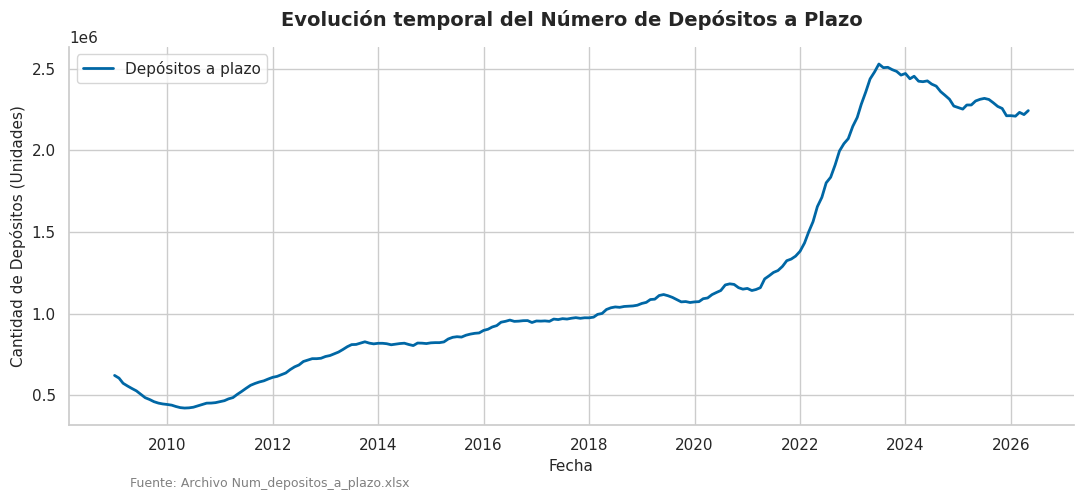

In [28]:
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(df['Fecha'], df['Valor'], color='#0067A5', linewidth=2, label='Depósitos a plazo')


# 1. Título descriptivo y Nombre del eje horizontal y vertical
ax.set_title('Evolución temporal del Número de Depósitos a Plazo', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Fecha', fontsize=11)
ax.set_ylabel('Cantidad de Depósitos (Unidades)', fontsize=11)

# 2. Leyenda
ax.legend(loc='upper left')

# 3. Contexto suficiente: Fuente de los datos
fig.text(0.125, 0.01, 'Fuente: Archivo Num_depositos_a_plazo.xlsx', fontsize=9, color='gray')


ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()


plt.show()

**Interpretación**

La serie temporal muestra una tendencia general al alza a lo largo del período evaluado (2009-2026). En sus inicios, experimentó un ligero descenso hasta alcanzar su nivel más bajo alrededor de 421.000 depósitos en el año 2010. Posteriormente, se observa un crecimiento constante y gradual durante toda la década, llegando a superar el millón de operaciones hacia 2018.

El cambio más importante y drástico ocurre entre los años 2022 y 2023, donde el número de depósitos se dispara rápidamente, alcanzando un máximo histórico superior a 2.5 millones de operaciones. Este comportamiento probablemente responde al aumento en las tasas de interés impulsado para contener la inflación, lo que volvió a este instrumento de ahorro sumamente atractivo. Finalmente, a partir de 2024 y hasta 2026, se aprecia una ligera corrección a la baja y posterior estabilización en torno a los 2.2 millones de depósitos, consolidando un nivel significativamente mayor al histórico.